# 8. Sparse Modeling and Compressed Sensing

Practice for week 8: orthogonal matching pursuit (OMP), DCT dictionaries for image patches, a small
K-SVD that learns a dictionary, sparse denoising, non-uniqueness in overcomplete dictionaries, using one
video frame as the dictionary for the next, and compressed sensing.

In [1]:
from math import comb
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))
    return img.clip(0, 1)

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

img = make_image()

## 8.1 Orthogonal matching pursuit

Greedy sparse coding of `x ≈ Dα`: pick the atom most correlated with the residual, refit all chosen
atoms by least squares, repeat until `L` atoms are used or the residual is small enough.

In [2]:
def omp(D, x, L=None, tol=None):
    r, S, coef = x.copy(), [], np.zeros(0)
    while len(S) < (L or D.shape[0]) and r @ r > (tol or 1e-9) ** 2:
        j = int(np.argmax(np.abs(D.T @ r)))
        if j in S: break                      # residual already orthogonal to the dictionary
        S.append(j)
        coef, *_ = np.linalg.lstsq(D[:, S], x, rcond=None)
        r = x - D[:, S] @ coef
    a = np.zeros(D.shape[1]); a[S] = coef
    return a

atoms = np.array([[0, 1], [1, 1], [0, 1], [2, 1]], float).T
norms = np.linalg.norm(atoms, axis=0)
alpha = omp(atoms / norms, np.array([2.0, 2.0]), L=1) / norms
print("atoms (0,1), (1,1), (0,1), (2,1); x = (2,2) -> alpha =", alpha)
print(f"supports of size 3 in 100 atoms: C(100, 3) = {comb(100, 3):,}; a GMM with 100 Gaussians: 100 subspaces")

atoms (0,1), (1,1), (0,1), (2,1); x = (2,2) -> alpha = [0. 2. 0. 0.]
supports of size 3 in 100 atoms: C(100, 3) = 161,700; a GMM with 100 Gaussians: 100 subspaces


## 8.2 DCT dictionaries for 8×8 patches

The complete 2D DCT (64 atoms, the JPEG basis) and an overcomplete DCT (121 atoms, a finer frequency
grid). Approximate random patches of the test image with L atoms.

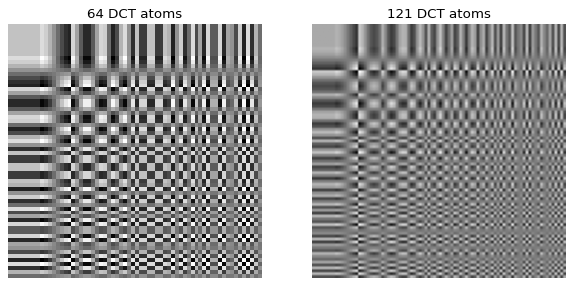

L = 1: RMSE complete DCT 0.1240, overcomplete DCT 0.1240
L = 2: RMSE complete DCT 0.0779, overcomplete DCT 0.0747


L = 4: RMSE complete DCT 0.0462, overcomplete DCT 0.0410


L = 8: RMSE complete DCT 0.0208, overcomplete DCT 0.0186


In [3]:
def dct_dict(n=8, k=8):
    D1 = np.cos(np.outer(np.arange(n) + 0.5, np.arange(k)) * np.pi / k)
    D1[:, 1:] -= D1[:, 1:].mean(0)
    D = np.kron(D1, D1)
    return D / np.linalg.norm(D, axis=0)

def patches(u, n, rng, size=8):
    ys, xs = rng.integers(0, u.shape[0] - size, n), rng.integers(0, u.shape[1] - size, n)
    return np.stack([u[y:y + size, x:x + size].ravel() for y, x in zip(ys, xs)], 1)

D64, D121 = dct_dict(8, 8), dct_dict(8, 11)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for a, D, k in [(axes[0], D64, 8), (axes[1], D121, 11)]:
    tiles = D.T.reshape(k, k, 8, 8).transpose(0, 2, 1, 3).reshape(8 * k, 8 * k)
    a.imshow(tiles, cmap="gray"); a.set_title(f"{k * k} DCT atoms"); a.axis("off")
plt.show()

X = patches(img, 1000, rng)
for L in [1, 2, 4, 8]:
    errs = [np.sqrt(np.mean((X - D @ np.stack([omp(D, x, L) for x in X.T], 1)) ** 2)) for D in (D64, D121)]
    print(f"L = {L}: RMSE complete DCT {errs[0]:.4f}, overcomplete DCT {errs[1]:.4f}")

## 8.3 Learning the dictionary (K-SVD)

Alternate sparse coding (OMP, L = 3) and a dictionary update: each atom and its coefficients are replaced
by the best rank-1 fit (SVD) of the residual of the patches that use it. Start from random image patches
and compare on held-out patches.

In [4]:
Xtr, Xte = patches(img, 3000, rng), patches(img, 1000, rng)
D = Xtr[:, rng.choice(Xtr.shape[1], 64, replace=False)].copy()
D /= np.linalg.norm(D, axis=0)
D_random = D.copy()

def code(D, X, L=3):
    return np.stack([omp(D, x, L) for x in X.T], 1)

for it in range(8):
    A = code(D, Xtr)
    for k in range(D.shape[1]):
        idx = np.nonzero(A[k])[0]
        if len(idx) == 0:
            D[:, k] = Xtr[:, rng.integers(Xtr.shape[1])]; D[:, k] /= np.linalg.norm(D[:, k]); continue
        E = Xtr[:, idx] - D @ A[:, idx] + np.outer(D[:, k], A[k, idx])
        U, s, Vt = np.linalg.svd(E, full_matrices=False)
        D[:, k], A[k, idx] = U[:, 0], s[0] * Vt[0]
    print(f"iteration {it + 1}: train RMSE {np.sqrt(np.mean((Xtr - D @ A) ** 2)):.4f}")

for name, Dk in [("complete DCT", D64), ("random patches", D_random), ("K-SVD", D)]:
    print(f"held-out RMSE with 3 atoms, {name:14s}: {np.sqrt(np.mean((Xte - Dk @ code(Dk, Xte)) ** 2)):.4f}")

iteration 1: train RMSE 0.0439


iteration 2: train RMSE 0.0349


iteration 3: train RMSE 0.0319


iteration 4: train RMSE 0.0308


iteration 5: train RMSE 0.0302


iteration 6: train RMSE 0.0299


iteration 7: train RMSE 0.0292


iteration 8: train RMSE 0.0287
held-out RMSE with 3 atoms, complete DCT  : 0.0598


held-out RMSE with 3 atoms, random patches: 0.0598
held-out RMSE with 3 atoms, K-SVD         : 0.0362


## 8.4 Denoising with a sparse prior

Code every overlapping patch of a noisy image with OMP until the residual drops to the noise level
(`‖r‖ ≤ 1.15 · σ · 8`), then average the overlapping reconstructions. The squared-error stopping rule
comes from the Gaussian noise assumption.

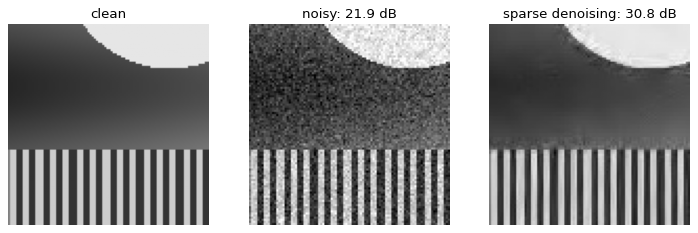

In [5]:
crop = img[120:216, 0:96]
sigma = 0.08
noisy = crop + rng.normal(0, sigma, crop.shape)
out, weight = np.zeros_like(crop), np.zeros_like(crop)
for y in range(0, 89, 2):
    for x in range(0, 89, 2):
        p = noisy[y:y + 8, x:x + 8].ravel()
        out[y:y + 8, x:x + 8] += (D121 @ omp(D121, p, tol=1.15 * sigma * 8)).reshape(8, 8)
        weight[y:y + 8, x:x + 8] += 1
den = out / weight
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for a, u, t in zip(axes, [crop, noisy, den], ["clean", f"noisy: {psnr(noisy, crop):.1f} dB", f"sparse denoising: {psnr(den, crop):.1f} dB"]):
    a.imshow(u, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

## 8.5 Overcomplete means non-unique

Concatenate two complete bases of R⁸ (DCT and the identity). A signal made of one cosine plus one spike
can be written with DCT atoms only, with identity atoms only, or with both. All three are exact. The
sparsity criterion is what picks the 2-atom answer.

In [6]:
C8 = np.array([[np.sqrt((1 if k == 0 else 2) / 8) * np.cos((2 * n + 1) * k * np.pi / 16) for k in range(8)] for n in range(8)])
I8 = np.eye(8)
sig = C8[:, 2] + 0.8 * I8[:, 5]
for name, Dk in [("DCT only", C8), ("identity only", I8), ("DCT + identity, OMP", np.hstack([C8, I8]))]:
    a = np.linalg.lstsq(Dk, sig, rcond=None)[0] if Dk.shape[1] == 8 else omp(Dk, sig, tol=1e-9)
    print(f"{name:20s}: {int((np.abs(a) > 1e-9).sum())} non-zeros, error {np.linalg.norm(Dk @ a - sig):.1e}")

DCT only            : 8 non-zeros, error 4.8e-16
identity only       : 8 non-zeros, error 0.0e+00
DCT + identity, OMP : 2 non-zeros, error 1.2e-16


## 8.6 One frame as the dictionary for the next

Use every 8×8 patch of frame t as an atom and code frame t+1 (the scene shifted by a few pixels) with a
single atom per block. Almost every block is found exactly, which is the temporal redundancy that video
codecs exploit with motion compensation.

In [7]:
f0 = img[100:164, 20:84]
f1 = img[102:166, 23:87]
Dv = np.stack([f0[y:y + 8, x:x + 8].ravel() for y in range(57) for x in range(57)], 1)
Dv_n = Dv / np.linalg.norm(Dv, axis=0)
blocks = [f1[y:y + 8, x:x + 8].ravel() for y in range(0, 64, 8) for x in range(0, 64, 8)]
err_frame = np.mean([np.linalg.norm(Dv_n @ omp(Dv_n, b, L=1) - b) / np.linalg.norm(b) for b in blocks])
err_dct = np.mean([np.linalg.norm(D64 @ omp(D64, b, L=1) - b) / np.linalg.norm(b) for b in blocks])
print(f"relative error with 1 atom per block: previous-frame dictionary {err_frame:.4f}, DCT {err_dct:.4f}")

relative error with 1 atom per block: previous-frame dictionary 0.0017, DCT 0.0764


## 8.7 Compressed sensing

Sparse modeling is about representing signals; compressed sensing is about acquiring them. A length-128
signal with 5 non-zeros is measured with m random projections `y = Φx`. For m well below 128, OMP
recovers it exactly, while the minimum-norm least-squares solution does not.

m = 40: OMP error 1.1e-15, minimum-norm error 1.53


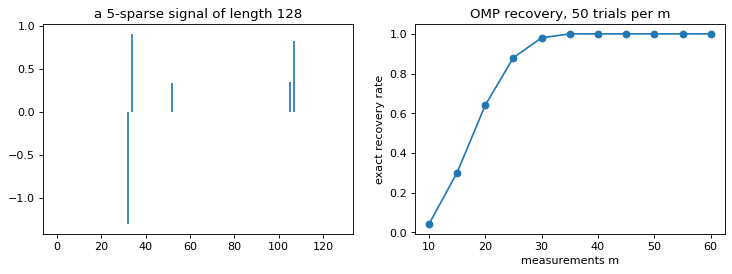

In [8]:
n, k = 128, 5
def trial(m, r):
    x = np.zeros(n); x[r.choice(n, k, replace=False)] = r.normal(0, 1, k)
    Phi = r.normal(0, 1, (m, n)) / np.sqrt(m)
    y = Phi @ x
    return x, Phi, y

x, Phi, y = trial(40, rng)
x_omp = omp(Phi / np.linalg.norm(Phi, axis=0), y, L=k) / np.linalg.norm(Phi, axis=0)
x_ls = np.linalg.pinv(Phi) @ y
print(f"m = 40: OMP error {np.linalg.norm(x_omp - x):.1e}, minimum-norm error {np.linalg.norm(x_ls - x):.2f}")

ms = range(10, 61, 5)
rate = []
for m in ms:
    ok = 0
    for _ in range(50):
        x, Phi, y = trial(m, rng); nrm = np.linalg.norm(Phi, axis=0)
        ok += np.linalg.norm(omp(Phi / nrm, y, L=k) / nrm - x) < 1e-6 * np.linalg.norm(x)
    rate.append(ok / 50)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].stem(trial(40, np.random.default_rng(1))[0], markerfmt=" ", basefmt=" ")
axes[0].set_title("a 5-sparse signal of length 128")
axes[1].plot(list(ms), rate, "o-"); axes[1].set_xlabel("measurements m"); axes[1].set_ylabel("exact recovery rate")
axes[1].set_title("OMP recovery, 50 trials per m"); plt.show()